# Hierarchical / Agglomerative Clustering

## 1. Definition
Agglomerative clustering starts with every observation as its own cluster and repeatedly merges two clusters until the requested number of clusters remains (or a stopping threshold is reached). The sequence of merges forms a dendrogram.

## 2. Linkage definitions
For clusters A and B:
- **Single linkage:** minimum pairwise point distance.
- **Complete linkage:** maximum pairwise point distance.
- **Average linkage:** average pairwise point distance.
- **Ward linkage:** merges the pair that yields the smallest increase in within-cluster sum of squares; this is naturally tied to Euclidean geometry.

Different linkage rules define different notions of cluster proximity, so they can produce different shapes.

## 3. Why it works and assumptions
Agglomerative clustering is a greedy hierarchy-building procedure, not a single global objective optimization for all linkages. Ward's method greedily minimizes the increase in within-cluster SSE at each merge, but a greedy sequence is not guaranteed to be globally optimal for every desired flat partition.

It is sensitive to scaling, distance choice, noise and linkage. It can expose nested structure but does not naturally assign a new observation to a learned hierarchy without an additional rule.

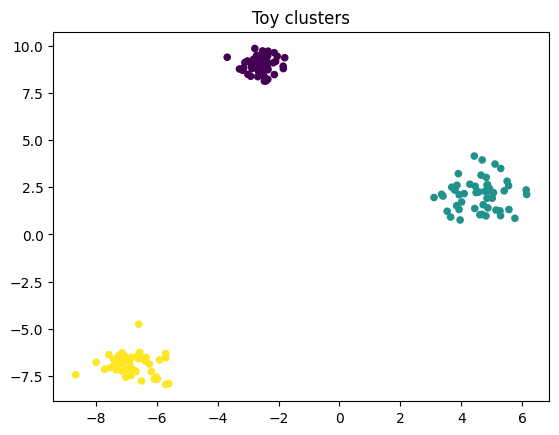

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

SEED = 42
X, y = make_blobs(n_samples=150, centers=3, cluster_std=[0.45, 0.8, 0.55], random_state=SEED)
plt.scatter(X[:,0], X[:,1], c=y, s=20)
plt.title("Toy clusters")
plt.show()


## 4. Single-linkage from scratch (small n only)
This transparent implementation repeatedly merges the two clusters with the closest pair of points. It uses pairwise distances and a naive scan over cluster pairs. This is intentionally not a high-performance implementation; the library implementations use more efficient data structures.

In [2]:
def agglomerative_single_linkage_scratch(X, n_clusters=3):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("X must be a non-empty finite 2D array")
    if not 1 <= n_clusters <= len(X):
        raise ValueError("n_clusters must be between 1 and n_samples")
    D = np.sqrt(np.maximum(0, np.sum((X[:,None,:]-X[None,:,:])**2, axis=2)))
    clusters = [{i} for i in range(len(X))]
    while len(clusters) > n_clusters:
        best_dist, best_pair = np.inf, None
        for i in range(len(clusters)):
            for j in range(i+1, len(clusters)):
                dist = min(D[a,b] for a in clusters[i] for b in clusters[j])
                if dist < best_dist:
                    best_dist, best_pair = dist, (i,j)
        i,j = best_pair
        clusters[i] = clusters[i] | clusters[j]
        del clusters[j]
    labels = np.empty(len(X), dtype=int)
    for label, cluster in enumerate(clusters):
        for idx in cluster:
            labels[idx] = label
    return labels

small = X[:80]
y_small = y[:80]
labels_scratch = agglomerative_single_linkage_scratch(small, n_clusters=3)
print("Scratch ARI on first 80 observations:", round(adjusted_rand_score(y_small, labels_scratch), 4))


Scratch ARI on first 80 observations: 1.0


## 5. Library implementation and dendrogram

Scikit-learn's API and SciPy's linkage utilities serve different use cases. The dendrogram below uses SciPy's single-linkage tree for a small sample.

sklearn single-linkage ARI: 1.0


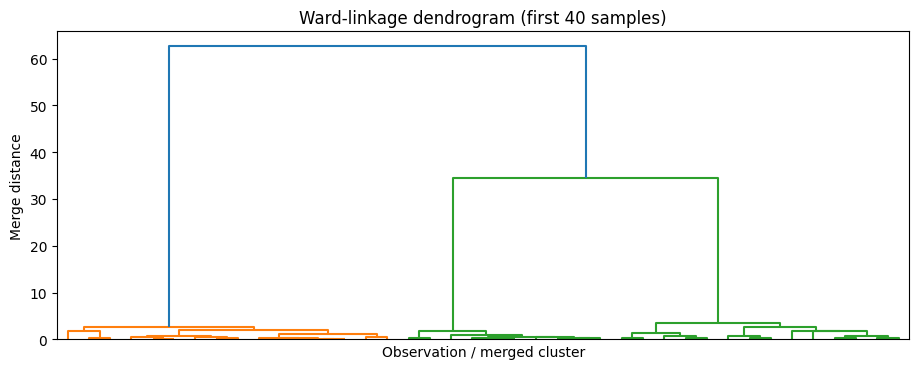

In [3]:
agg = AgglomerativeClustering(n_clusters=3, linkage="single").fit(X)
print("sklearn single-linkage ARI:", round(adjusted_rand_score(y, agg.labels_), 4))
Z = linkage(X[:40], method="ward")
plt.figure(figsize=(11,4))
dendrogram(Z, no_labels=True)
plt.title("Ward-linkage dendrogram (first 40 samples)")
plt.xlabel("Observation / merged cluster"); plt.ylabel("Merge distance")
plt.show()


## 6. Hyperparameters, complexity, and scaling

- `n_clusters`: number of final clusters.
- `linkage`: single, complete, average or Ward.
- `metric`: distance definition; Ward requires Euclidean geometry in common implementations.
- Pairwise distances require \(O(n^2)\) storage and often \(O(n^2d)\) work; naive repeated merging can be much worse than optimized methods.
- Dense hierarchical clustering may be infeasible for millions of samples. Consider BIRCH, sampling, sparse nearest-neighbor graphs or methods designed for scale.
- GPU acceleration depends on distance-graph construction and implementation; it does not remove the quadratic memory issue.

## 7. Best practices and synthesis
Plot dendrograms on manageable samples, standardize when needed, compare linkage rules, and validate clusters against domain requirements rather than selecting a cut solely by appearance. A hierarchy contains more information than one flat clustering, but can be computationally expensive.

In [4]:
assert labels_scratch.shape == (len(small),)
assert len(np.unique(labels_scratch)) == 3
try:
    agglomerative_single_linkage_scratch(np.array([1,2,3]), 2)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid input shape to raise")
print("All hierarchical clustering checks passed.")


All hierarchical clustering checks passed.
